In [122]:
import pandas as pd
import kagglehub
from kagglehub import KaggleDatasetAdapter
import os

In [123]:

# Set the path to the file you'd like to load
# Para este dataset específico, el archivo se llama 'credit_risk_dataset.csv'
file_path = "loan/loan.csv"

# Load the latest version
df_og = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "ranadeep/credit-risk-dataset",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)
print("First 5 records:")
df_og.head()


/tmp/ipykernel_8606/3234964599.py:6: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df_og = kagglehub.load_dataset(
/home/tomasgomez/Github/RedesNeuronales_Trabajo2/.venv/lib64/python3.14/site-packages/kagglehub/pandas_datasets.py:92: DtypeWarning: Columns (19: desc, 55: verification_status_joint) have mixed types. Specify dtype option on import or set low_memory=False.
  result = read_function(


First 5 records:


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,1077501,1296599,5000.0,5000.0,4975.0,36 months,10.65,162.87,B,B2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1077430,1314167,2500.0,2500.0,2500.0,60 months,15.27,59.83,C,C4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1077175,1313524,2400.0,2400.0,2400.0,36 months,15.96,84.33,C,C5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1076863,1277178,10000.0,10000.0,10000.0,36 months,13.49,339.31,C,C1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1075358,1311748,3000.0,3000.0,3000.0,60 months,12.69,67.79,B,B5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [124]:
df_og.shape



(887379, 74)

In [125]:
df = df_og.copy()

# 1. Definir el diccionario de mapeo para 0 y 1
mapping = {
    'Fully Paid': 0,
    'Does not meet the credit policy. Status:Fully Paid': 0,
    'Charged Off': 1,
    'Default': 1,
    'Late (31-120 days)': 1,
    'Does not meet the credit policy. Status:Charged Off': 1
}

# 2. Filtrar únicamente los casos válidos (excluyendo los NA)
df = df[df['loan_status'].isin(mapping.keys())].copy()

df['issue_d'] = pd.to_datetime(df['issue_d'], format='%b-%Y')

# 3. Crear la nueva variable objetivo binaria
df['loan_status'] = df['loan_status'].map(mapping)


In [126]:
df.shape

(268530, 74)

In [127]:
columnas_id = ["id", "member_id", "policy_code"]
columnas_fechas = ["last_pymnt_d", "next_pymnt_d", "last_credit_pull_d"]
columnas_alta_cardinalidad = [ "url",  "emp_title", "desc", "title", "zip_code", "earliest_cr_line"]
columnas_fuga_datos = [
    'out_prncp', 
    'out_prncp_inv', 
    'total_pymnt', 
    'total_pymnt_inv', 
    'total_rec_prncp', 
    'total_rec_int', 
    'total_rec_late_fee', 
    'recoveries', 
    'collection_recovery_fee', 
    'last_pymnt_amnt'
]

columnas_a_excluir = columnas_id + columnas_fechas + columnas_alta_cardinalidad + columnas_fuga_datos
df = df.drop(columns=columnas_a_excluir)

In [128]:
# 1. Conteo de nulos por columna
conteo_nulos = df.isnull().sum()

# 2. Porcentaje de nulos respecto al total de filas
porcentaje_nulos = (df.isnull().mean() * 100).round(2)

# 3. Unir ambos resultados en un DataFrame ordenado de mayor a menor porcentaje
df_resumen_nulos = pd.DataFrame({
    'Nulos': conteo_nulos,
    'Porcentaje (%)': porcentaje_nulos
}).sort_values(by='Porcentaje (%)', ascending=False)

print(df_resumen_nulos)


                              Nulos  Porcentaje (%)
verification_status_joint    268527          100.00
annual_inc_joint             268527          100.00
dti_joint                    268527          100.00
inq_last_12m                 268386           99.95
open_acc_6m                  268386           99.95
open_il_6m                   268386           99.95
open_il_12m                  268386           99.95
open_il_24m                  268386           99.95
total_bal_il                 268386           99.95
mths_since_rcnt_il           268390           99.95
il_util                      268404           99.95
open_rv_12m                  268386           99.95
inq_fi                       268386           99.95
open_rv_24m                  268386           99.95
max_bal_bc                   268386           99.95
all_util                     268386           99.95
total_cu_tl                  268386           99.95
mths_since_last_record       233873           87.09
mths_since_l

In [129]:
columnas_con_nulos = [
    'annual_inc_joint',
    'verification_status_joint',
    'dti_joint',
    'il_util',
    'mths_since_rcnt_il',
    'inq_fi',
    'open_rv_24m',
    'open_acc_6m',
    'all_util',
    'inq_last_12m',
    'total_cu_tl',
    'open_il_12m',
    'max_bal_bc',
    'open_il_6m',
    'open_il_24m',
    'open_rv_12m',
    'total_bal_il',
    'desc',
    'mths_since_last_record',
    'mths_since_last_major_derog',
    'mths_since_last_delinq',
    'next_pymnt_d'
]

# Eliminar las columnas del DataFrame (axis=1 indica columnas)
df = df.drop(columns=columnas_con_nulos, errors='ignore')

print(f"Columnas restantes en el DataFrame: {df.shape[1]}")


Columnas restantes en el DataFrame: 32


In [130]:
columnas_con_nulos = [
    'total_rev_hi_lim',
    'tot_cur_bal',
    'tot_coll_amt',
    'emp_length',
    'revol_util',
    'collections_12_mths_ex_med'
]

df = df.dropna(subset=columnas_con_nulos).copy()

In [131]:
categoricas = df.select_dtypes(include=['object', 'category'])
numericas = df.select_dtypes(include=['number']).copy().drop(columns=["loan_status"])

/tmp/ipykernel_8606/2539652475.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = df.select_dtypes(include=['object', 'category'])


In [132]:
# %%
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import f_classif

# 1. Definir X (solo variables numéricas normalizadas) y 'y' (target)
X_num = numericas
y = df['loan_status'] 

# 2. Calcular los F-Scores y los valores p
f_scores, p_values = f_classif(X_num, y)

# 3. Crear el DataFrame y ordenar de mayor a menor significancia
df_significancia = pd.DataFrame({
    'Variable': X_num.columns,
    'F_Score': f_scores,
    'P_Value': p_values
}).sort_values(by='F_Score', ascending=False)

# Imprimir todas las filas en la consola (to_string evita que pandas oculte filas)
print("Significancia de TODAS las variables numéricas (ANOVA):")
print(df_significancia.to_string(index=False))



Significancia de TODAS las variables numéricas (ANOVA):
                  Variable      F_Score       P_Value
                  int_rate 13106.614576  0.000000e+00
                       dti  3680.207371  0.000000e+00
                revol_util  1762.410560  0.000000e+00
               tot_cur_bal  1135.604219 3.194151e-248
           funded_amnt_inv   798.571496 2.518934e-175
                 loan_amnt   797.026196 5.442659e-175
               funded_amnt   796.788615 6.127080e-175
                annual_inc   709.764623 4.322890e-156
          total_rev_hi_lim   572.722243 2.197434e-126
               installment   458.134943 1.607436e-101
            inq_last_6mths   415.743748  2.578803e-92
                 total_acc   342.735228  1.886104e-76
               delinq_2yrs   135.287581  2.925997e-31
                  open_acc    59.342619  1.331019e-14
collections_12_mths_ex_med    42.491561  7.116175e-11
            acc_now_delinq    22.473097  2.132591e-06
                 revol_bal

In [133]:
columnas_numericas_no_significativas = ["pub_rec", "tot_coll_amt"]

numericas = numericas.drop(columns=columnas_numericas_no_significativas)
df = df.drop(columns=columnas_numericas_no_significativas)

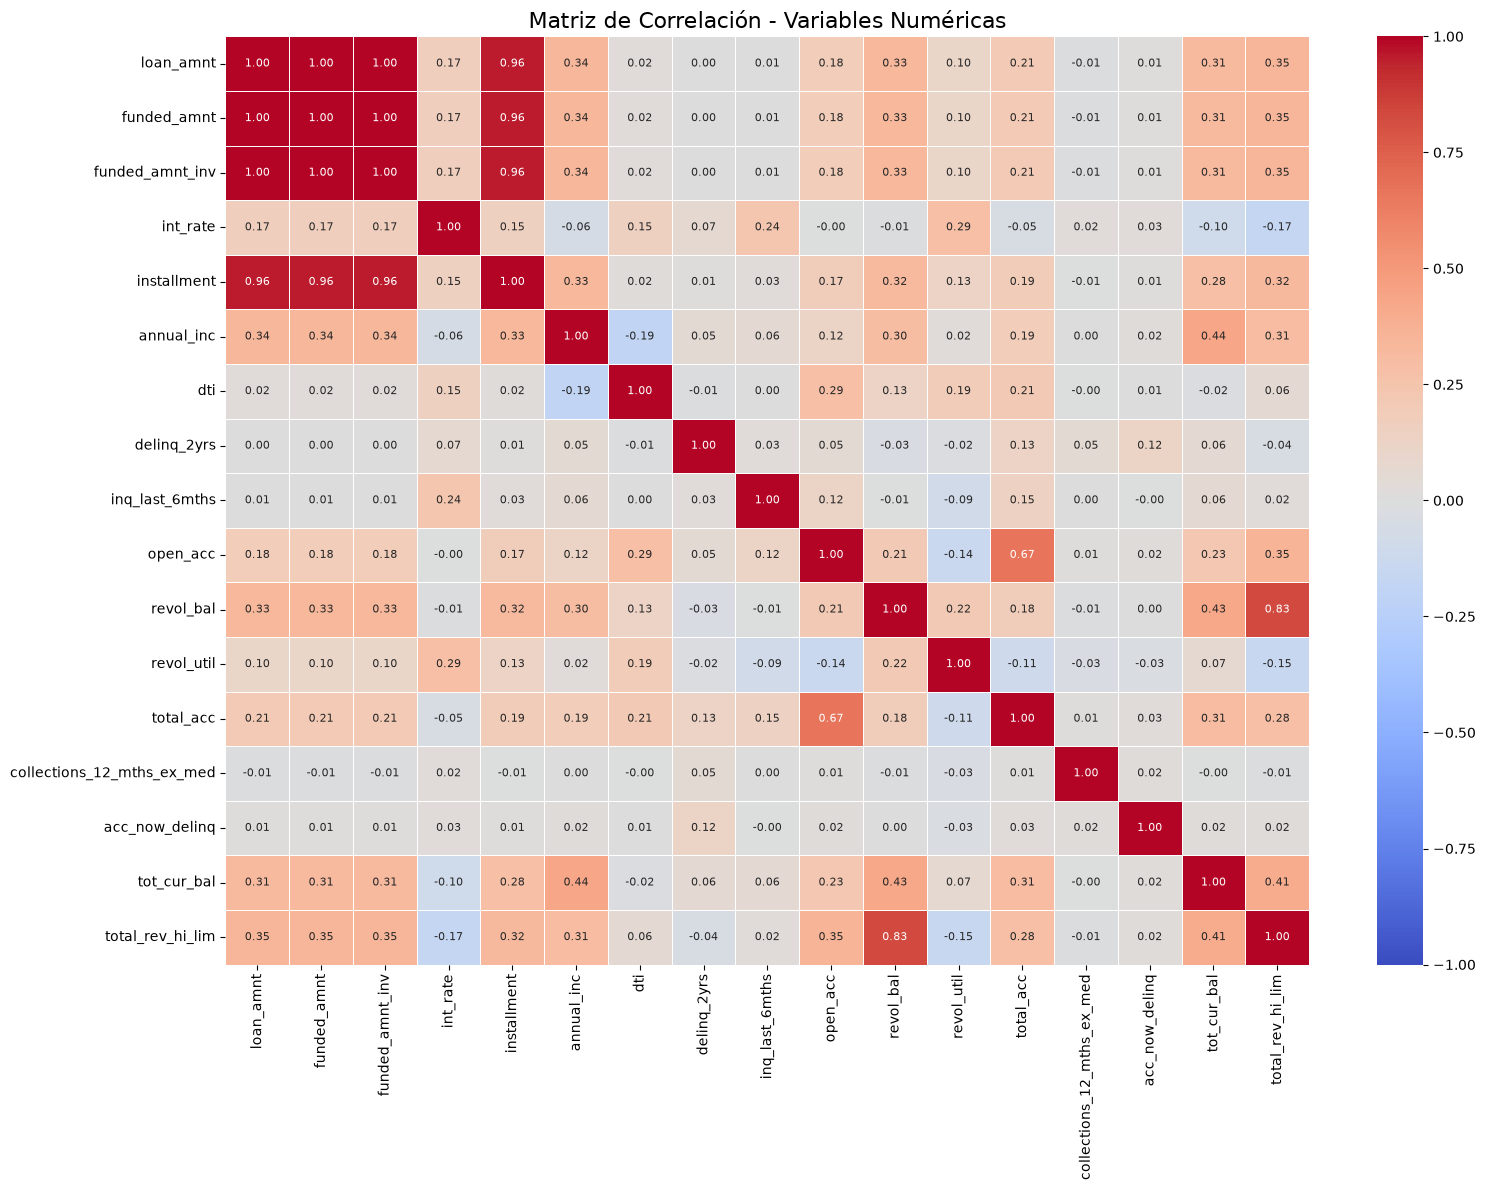

In [134]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcula la matriz de correlación de Pearson
matriz_corr_num = numericas.corr()

# Configura y muestra el mapa de calor con los números
plt.figure(figsize=(16, 12))  # Figura un poco más grande para acomodar los números
sns.heatmap(matriz_corr_num, 
            annot=True,       # Muestra los valores numéricos
            fmt=".2f",        # Redondea a 2 decimales
            cmap='coolwarm', 
            vmin=-1, vmax=1, 
            linewidths=0.5,
            annot_kws={"size": 8})  # Tamaño de fuente más pequeño para los números
plt.title('Matriz de Correlación - Variables Numéricas', fontsize=16)
plt.tight_layout()
plt.show()

In [135]:
columnas_numericas_redundates = ["funded_amnt", "funded_amnt_inv", "installment", "total_rev_hi_lim"]

numericas = numericas.drop(columns=columnas_numericas_redundates)
df = df.drop(columns=columnas_numericas_redundates)

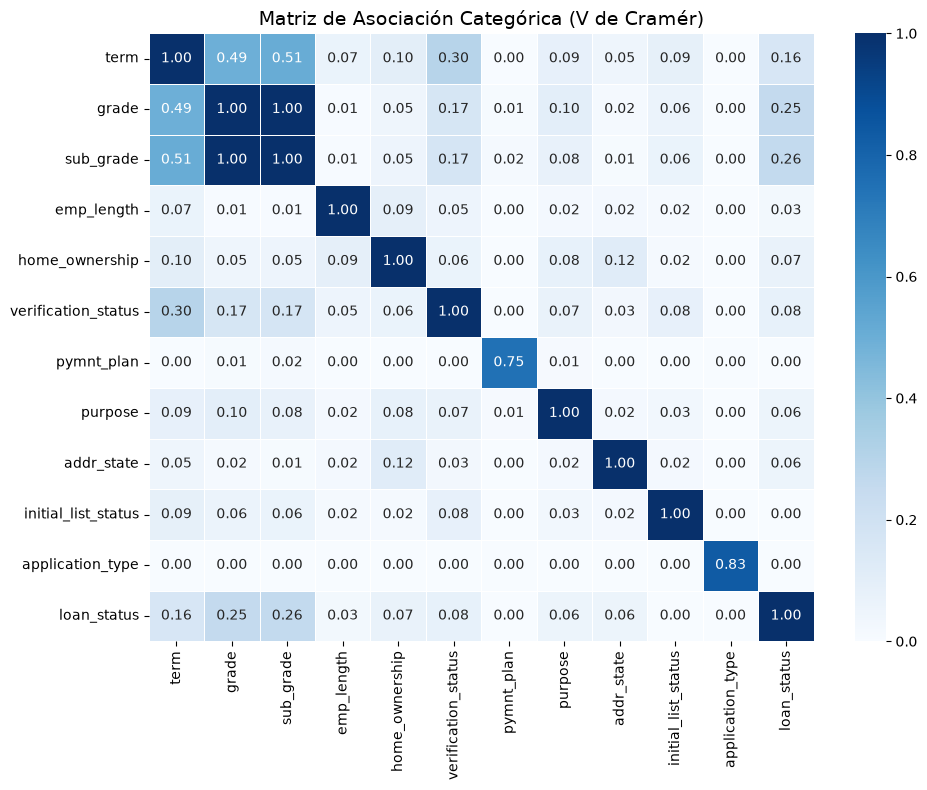

In [136]:
# %%
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# Copiar las categóricas sin 'grade'
categoricas1 = categoricas.copy()

# AÑADIR LA VARIABLE OBJETIVO (Asegúrate de tomarla del dataframe que la contenga, por ejemplo 'df')
categoricas1['loan_status'] = df['loan_status']

# 1. Definir la función de V de Cramér
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    
    if n == 0 or r == 1 or k == 1:
        return 0.0
        
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

# 2. Crear una matriz vacía 
columnas_cat = categoricas1.columns
matriz_cramer = pd.DataFrame(index=columnas_cat, columns=columnas_cat)

# 3. Calcular la V de Cramér para cada par de variables
for col1 in columnas_cat:
    for col2 in columnas_cat:
        matriz_cramer.loc[col1, col2] = cramers_v(categoricas1[col1], categoricas1[col2])

matriz_cramer = matriz_cramer.astype(float)

# 4. Visualizar en un Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_cramer, 
            annot=True,          
            cmap='Blues',        
            fmt=".2f", 
            vmin=0, vmax=1,
            linewidths=0.5)
plt.title('Matriz de Asociación Categórica (V de Cramér)', fontsize=14)
plt.tight_layout()
plt.show()

In [137]:
categoricas.columns

Index(['term', 'grade', 'sub_grade', 'emp_length', 'home_ownership',
       'verification_status', 'pymnt_plan', 'purpose', 'addr_state',
       'initial_list_status', 'application_type'],
      dtype='str')

In [138]:
columnas_categoricas_no_signifiativas = ["emp_length", "pymnt_plan", "initial_list_status", "application_type"]

columnas_categoricas_redundates = ["grade"]

categoricas = categoricas.drop(columns=columnas_categoricas_no_signifiativas+columnas_categoricas_redundates)
df = df.drop(columns=columnas_categoricas_no_signifiativas+columnas_categoricas_redundates)

In [139]:
# print("emp_length: " + str(list((df['emp_length'].unique()))))
# print("grade: " + str(list((df['grade'].unique()))))
print("sub_grade: " + str(list((df['sub_grade'].unique()))))
print("verification_status: " + str(list((df['verification_status'].unique()))))

sub_grade: ['B5', 'B4', 'A3', 'B2', 'C2', 'B3', 'C1', 'B1', 'A1', 'C3', 'C5', 'E1', 'D2', 'E4', 'A5', 'A4', 'E5', 'D5', 'D1', 'F1', 'C4', 'E2', 'D3', 'G3', 'D4', 'G1', 'F2', 'F4', 'F5', 'G5', 'G4', 'F3', 'A2', 'E3', 'G2']
verification_status: ['Source Verified', 'Verified', 'Not Verified']


In [140]:
# # 1. Mapeo para 'grade' (de menor a mayor riesgo, A es mejor que G)
# grade_mapping = {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6}
# df['grade'] = df['grade'].map(grade_mapping)

# 2. Mapeo automático/ordenado para 'sub_grade' (A1 a G5)
letras = ['A', 'B', 'C', 'D', 'E', 'F', 'G']
subgrade_mapping = {f"{l}{n}": i for i, (l, n) in enumerate(
    (l, n) for l in letras for n in range(1, 6)
)}
df['sub_grade'] = df['sub_grade'].map(subgrade_mapping)

# 3. Mapeo para 'verification_status' (ordenado por nivel de rigor)
verification_mapping = {'Not Verified': 0, 'Source Verified': 1, 'Verified': 2}
df['verification_status'] = df['verification_status'].map(verification_mapping)


# # Mapeo ordenado para 'emp_length' (los nulos se pueden dejar como -1 o NaN)
# emp_length_mapping = {
#     '< 1 year': 0,
#     '1 year': 1,
#     '2 years': 2,
#     '3 years': 3,
#     '4 years': 4,
#     '5 years': 5,
#     '6 years': 6,
#     '7 years': 7,
#     '8 years': 8,
#     '9 years': 9,
#     '10+ years': 10
# }

# # Aplicar el mapeo conservando el nombre de la columna
# df['emp_length'] = df['emp_length'].map(emp_length_mapping)

In [141]:
# Selección de columnas no numéricas:
columns_to_dummy = df.select_dtypes(exclude=['number', "datetime"])

# Vista de columnas no numéricas.
columns_to_dummy.head()

,term,home_ownership,purpose,addr_state
42538,36 months,RENT,debt_consolidation,NM
42544,36 months,RENT,debt_consolidation,FL
42546,36 months,MORTGAGE,debt_consolidation,CA
42549,36 months,MORTGAGE,credit_card,MI
42550,36 months,MORTGAGE,debt_consolidation,CO


In [142]:
# Función auxiliar (generada con Gemini)
# Codificación con one-hot pero utilizando -1/1 en lugar de 0/1.
def dummy_encode(df, column):
    """
    Encodes a categorical column into dummy variables using -1/1 encoding.

    Args:
        df: The input DataFrame.
        column: The name of the column to encode.

    Returns:
        A DataFrame with the dummy variables.
    """

    dummies = pd.get_dummies(df[column], prefix=column, prefix_sep='_', drop_first=True)
    dummies = dummies.map(lambda x: 1 if x == 1 else 0)  # Convert 0s to -1s
    return pd.concat([df.drop(column, axis=1), dummies], axis=1)

In [143]:
# Aplicación de la función auxiliar para hacer el one-hot encoding:
dummy_encoded = columns_to_dummy.copy()

for column in dummy_encoded.columns:
    dummy_encoded = dummy_encode(dummy_encoded, column)

# Visualización del dataframe recodificado
dummy_encoded.head()

,term_ 60 months,home_ownership_MORTGAGE,home_ownership_NONE,home_ownership_OTHER,home_ownership_OWN,home_ownership_RENT,purpose_credit_card,purpose_debt_consolidation,purpose_home_improvement,purpose_house,...,addr_state_SD,addr_state_TN,addr_state_TX,addr_state_UT,addr_state_VA,addr_state_VT,addr_state_WA,addr_state_WI,addr_state_WV,addr_state_WY
42538,0,0,0,0,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
42544,0,0,0,0,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
42546,0,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
42549,0,1,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
42550,0,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


In [144]:
# Selección de las columnas numéricas:
numeric_cols = df.drop(columns_to_dummy.columns.tolist()+["loan_status"], axis=1)

# Display the first few rows of the selected numeric columns
numeric_cols.head()


,loan_amnt,int_rate,sub_grade,annual_inc,verification_status,issue_d,dti,delinq_2yrs,inq_last_6mths,open_acc,revol_bal,revol_util,total_acc,collections_12_mths_ex_med,acc_now_delinq,tot_cur_bal
42538,12000.0,13.53,9,40000.0,1,2013-12-01,16.94,0.0,0.0,7.0,5572.0,68.8,32.0,0.0,0.0,13605.0
42544,3000.0,12.85,8,25000.0,2,2013-12-01,24.68,0.0,0.0,5.0,2875.0,54.2,26.0,0.0,0.0,19530.0
42546,28000.0,7.62,2,325000.0,1,2013-12-01,18.55,0.0,1.0,15.0,29581.0,54.6,31.0,0.0,0.0,799592.0
42549,24000.0,13.53,9,100000.0,2,2013-12-01,22.18,0.0,0.0,14.0,21617.0,76.7,39.0,0.0,0.0,199834.0
42550,8000.0,10.99,6,33000.0,0,2013-12-01,15.75,0.0,1.0,9.0,7203.0,34.6,16.0,0.0,0.0,15949.0


In [145]:
df_final = pd.concat([numericas, dummy_encoded, df['loan_status'], df["issue_d"]], axis=1)
df_final.head()

,loan_amnt,int_rate,annual_inc,dti,delinq_2yrs,inq_last_6mths,open_acc,revol_bal,revol_util,total_acc,...,addr_state_TX,addr_state_UT,addr_state_VA,addr_state_VT,addr_state_WA,addr_state_WI,addr_state_WV,addr_state_WY,loan_status,issue_d
42538,12000.0,13.53,40000.0,16.94,0.0,0.0,7.0,5572.0,68.8,32.0,...,0,0,0,0,0,0,0,0,0,2013-12-01
42544,3000.0,12.85,25000.0,24.68,0.0,0.0,5.0,2875.0,54.2,26.0,...,0,0,0,0,0,0,0,0,0,2013-12-01
42546,28000.0,7.62,325000.0,18.55,0.0,1.0,15.0,29581.0,54.6,31.0,...,0,0,0,0,0,0,0,0,0,2013-12-01
42549,24000.0,13.53,100000.0,22.18,0.0,0.0,14.0,21617.0,76.7,39.0,...,0,0,0,0,0,0,0,0,0,2013-12-01
42550,8000.0,10.99,33000.0,15.75,0.0,1.0,9.0,7203.0,34.6,16.0,...,0,0,0,0,0,0,0,0,1,2013-12-01


In [146]:
df_final.describe()

,loan_amnt,int_rate,annual_inc,dti,delinq_2yrs,inq_last_6mths,open_acc,revol_bal,revol_util,total_acc,...,addr_state_TX,addr_state_UT,addr_state_VA,addr_state_VT,addr_state_WA,addr_state_WI,addr_state_WV,addr_state_WY,loan_status,issue_d
count,193050.000000,193050.000000,1.930500e+05,193050.000000,193050.000000,193050.000000,193050.000000,1.930500e+05,193050.000000,193050.000000,...,193050.000000,193050.000000,193050.000000,193050.000000,193050.000000,193050.000000,193050.000000,193050.000000,193050.000000,193050
mean,14413.481870,14.355545,7.479068e+04,17.417646,0.293074,0.855478,11.441849,1.579471e+04,55.443828,25.946905,...,0.078819,0.008853,0.031059,0.001611,0.023574,0.012411,0.004481,0.002388,0.233023,2014-01-07 17:34:28.699300
min,1000.000000,5.320000,6.000000e+03,0.000000,0.000000,0.000000,1.000000,0.000000e+00,0.000000,2.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2012-08-01 00:00:00
25%,8000.000000,11.140000,4.700000e+04,11.480000,0.000000,0.000000,8.000000,6.308000e+03,38.200000,17.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2013-05-01 00:00:00
50%,12175.000000,14.090000,6.500000e+04,17.000000,0.000000,1.000000,11.000000,1.138800e+04,56.600000,24.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2014-01-01 00:00:00
75%,20000.000000,17.270000,9.000000e+04,23.050000,0.000000,1.000000,14.000000,1.967900e+04,74.000000,33.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2014-09-01 00:00:00
max,35000.000000,28.990000,8.706582e+06,57.140000,29.000000,7.000000,76.000000,1.746716e+06,892.300000,150.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2015-12-01 00:00:00
std,8247.627782,4.455059,5.953106e+04,7.918548,0.816786,1.075071,4.999304,2.000620e+04,23.777016,11.803717,...,0.269457,0.093671,0.173478,0.040105,0.151719,0.110713,0.066788,0.048809,0.422758,NaN


In [147]:
carpeta_destino = '../datasets'
os.makedirs(carpeta_destino, exist_ok=True)

# 2. Definir la ruta completa del archivo Excel
ruta = os.path.join(carpeta_destino, 'df_procesado.csv')

# 3. Exportar el DataFrame a Excel (index=False evita guardar el índice numérico)
df_final.to_csv(ruta, index=False)

print(f"Archivo guardado correctamente en: {ruta}")

Archivo guardado correctamente en: ../datasets/df_procesado.csv


In [ ]:
print("Todas las columnas numericas")

list(numericas.columns)

['loan_amnt',
 'int_rate',
 'annual_inc',
 'dti',
 'delinq_2yrs',
 'inq_last_6mths',
 'open_acc',
 'revol_bal',
 'revol_util',
 'total_acc',
 'collections_12_mths_ex_med',
 'acc_now_delinq',
 'tot_cur_bal']

In [ ]:
print("Todas las columnas cualitativas, antres de ser tranformadas a label encoding y dummies")

list(categoricas.columns)

['term',
 'sub_grade',
 'home_ownership',
 'verification_status',
 'purpose',
 'addr_state']

In [ ]:
print("Columna de tiempo para evaluar")

list(df.select_dtypes("datetime"))

['issue_d']

In [ ]:
print("Todas las columnas, incluida la objetivo: loan_status")
list(df.columns)

['loan_amnt',
 'term',
 'int_rate',
 'sub_grade',
 'home_ownership',
 'annual_inc',
 'verification_status',
 'issue_d',
 'loan_status',
 'purpose',
 'addr_state',
 'dti',
 'delinq_2yrs',
 'inq_last_6mths',
 'open_acc',
 'revol_bal',
 'revol_util',
 'total_acc',
 'collections_12_mths_ex_med',
 'acc_now_delinq',
 'tot_cur_bal']